# ⚙️ 02. Feature Engineering, Preprocessing & Non-IID Partitioning

### **Leakage-Free Time-Series Pipeline for Federated Energy Theft Detection**
In federated smart grid deployments, data preprocessing must satisfy two strict criteria:
1. **Zero Data Leakage**: Normalization scalers and imputation medians must be fit *strictly* on training partitions.
2. **Multi-Variate Feature Representations**: Extracting first-order temporal differences, rolling statistics, cyclical time embeddings, and meter operational events.
3. **Non-IID Partitioning**: Segmenting datasets across 5 distribution substations (`client_A` to `client_E`) with realistic feeder variance.

In [2]:
import sys
import os
from pathlib import Path
import warnings
warnings.filterwarnings('ignore')

workspace_root = Path.cwd()
if workspace_root.name == "notebooks" or not (workspace_root / "fl_system").exists():
    workspace_root = workspace_root.parent
if str(workspace_root) not in sys.path:
    sys.path.insert(0, str(workspace_root))

print(f"✓ Project Root: {workspace_root}")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from fl_system.models.dataset import (
    TimeSeriesPreprocessor,
    extract_multivariate_features,
    create_sequence_windows,
    MeterSequenceDataset,
    STATUS_MAPPING,
    EVENT_MAPPING
)

plt.style.use('seaborn-v0_8-whitegrid' if 'seaborn-v0_8-whitegrid' in plt.style.available else 'default')
plt.rcParams['figure.dpi'] = 120

✓ Project Root: d:\users\Group Project\Blockchain-Based Byzantine-Resilient Federated Learning for Smart Grid Energy Theft Detection


## 1. Zero-Leakage Preprocessing Engine

The `TimeSeriesPreprocessor` class fits min-max or z-score parameters exclusively on training data, preventing future validation or test values from skewing the scaling parameters.

$$\mu = rac{1}{N_{	ext{train}}} \sum_{i \in 	ext{train}} x_i, \quad \sigma = \sqrt{rac{1}{N_{	ext{train}}} \sum_{i \in 	ext{train}} (x_i - \mu)^2}$$

$$x_{	ext{norm}} = rac{x - x_{	ext{train,min}}}{x_{	ext{train,max}} - x_{	ext{train,min}}}$$

In [3]:
# Create sample telemetry with missing values and outliers
timestamps = pd.date_range("2026-01-01", periods=168, freq="h")
raw_vals = 3.0 + 1.5 * np.sin(2 * np.pi * np.arange(168) / 24) + np.random.normal(0, 0.3, 168)
raw_vals[15:18] = np.nan  # Simulating communication dropout

sample_df = pd.DataFrame({
    "timestamp": timestamps,
    "meter_id": ["MTR_TEST_01"] * 168,
    "consumption_kwh": raw_vals,
    "meter_status": ["NORMAL"] * 168,
    "event_type": ["NONE"] * 168,
    "hardware_tamper_flag": [0] * 168,
    "simulated_theft_label": [0] * 168
})

train_df = sample_df.iloc[:120].copy()
test_df = sample_df.iloc[120:].copy()

preprocessor = TimeSeriesPreprocessor(scaling="minmax")
preprocessor.fit(train_df, consumption_col="consumption_kwh")

print("Fitted Preprocessor State (Derived Strictly from Training Set):")
print(f"  Min Consumption: {preprocessor.state.min_consumption:.3f} kWh")
print(f"  Max Consumption: {preprocessor.state.max_consumption:.3f} kWh")
print(f"  Training Median Impute Value: {preprocessor.state.median_impute_value:.3f} kWh")

train_transformed = preprocessor.transform(train_df)
test_transformed = preprocessor.transform(test_df)

print(f"\nTransformed Train bounds: [{train_transformed['norm_consumption'].min():.2f}, {train_transformed['norm_consumption'].max():.2f}]")
print(f"Transformed Test bounds:  [{test_transformed['norm_consumption'].min():.2f}, {test_transformed['norm_consumption'].max():.2f}]")

Fitted Preprocessor State (Derived Strictly from Training Set):
  Min Consumption: 0.775 kWh
  Max Consumption: 5.038 kWh
  Training Median Impute Value: 3.013 kWh

Transformed Train bounds: [0.00, 1.00]
Transformed Test bounds:  [0.11, 0.98]


## 2. Multivariate Feature Engineering (11 Features)

To provide neural networks with full temporal context and distinguish legitimate load drops (e.g. grid outages, solar self-generation) from unauthorized energy theft, we extract 11 distinct features:

| Index | Feature Name | Description | Role in Theft Discrimination |
| :---: | :--- | :--- | :--- |
| **0** | `norm_consumption` | Min-Max normalized hourly consumption | Primary consumption magnitude |
| **1** | `consumption_delta` | First-order difference: $c_t - c_{t-1}$ | Identifies sharp transition boundaries and bypass kicks |
| **2** | `rolling_mean_6h` | 6-hour moving average | Smooths transient noise to reveal sustained suppression |
| **3** | `rolling_std_6h` | 6-hour moving standard deviation | Flatline detection: theft often shows unnaturally zero variance |
| **4-5** | `sin_hour`, `cos_hour` | Cyclical time-of-day encoding ($rac{2\pi t}{24}$) | Captures diurnal schedule patterns |
| **6-7** | `sin_dow`, `cos_dow` | Cyclical day-of-week encoding ($rac{2\pi d}{7}$) | Captures weekend vs weekday industrial patterns |
| **8** | `meter_status_enc` | Operational meter status mapping | Distinguishes communication failures from theft |
| **9** | `event_type_enc` | AMI grid event mapping | Accounts for solar PV generation and scheduled outages |
| **10** | `hardware_tamper_flag`| Hardware optical/magnetic tamper flag | Direct physical sensor trigger |

Extracted Feature Matrix Shape: (120, 11)
Feature Names (11):
  [00] norm_consumption
  [01] consumption_delta
  [02] rolling_mean_6h
  [03] rolling_std_6h
  [04] sin_hour
  [05] cos_hour
  [06] sin_dow
  [07] cos_dow
  [08] meter_status_enc
  [09] event_type_enc
  [10] hardware_tamper_flag


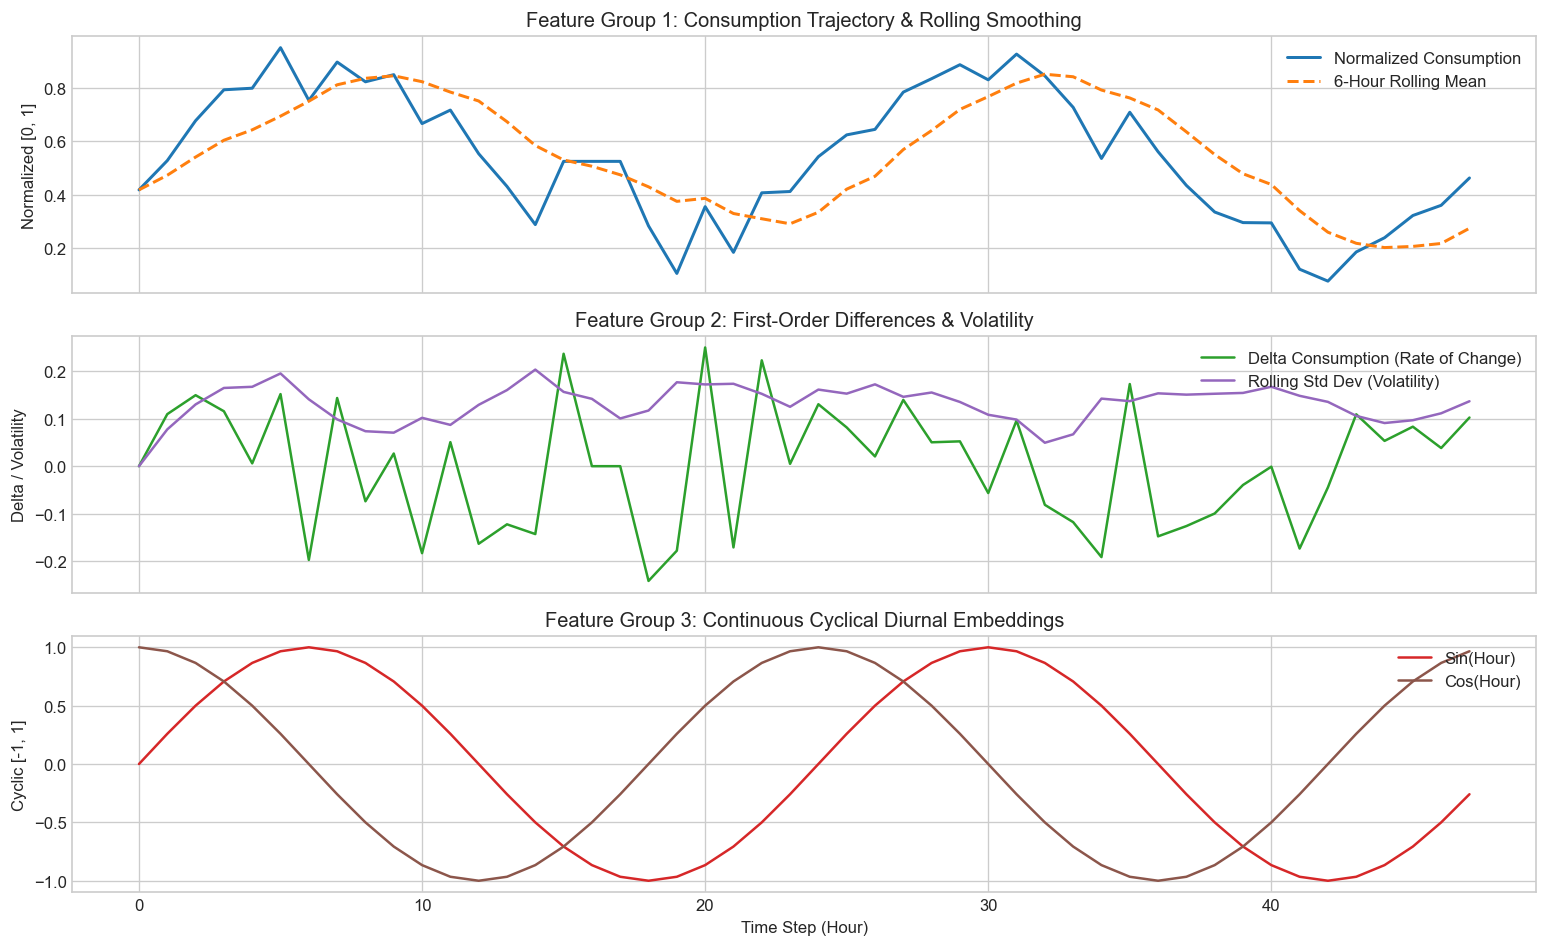

In [4]:
features_mat, feature_names = extract_multivariate_features(train_transformed)

print(f"Extracted Feature Matrix Shape: {features_mat.shape}")
print(f"Feature Names ({len(feature_names)}):")
for i, name in enumerate(feature_names):
    print(f"  [{i:02d}] {name}")

df_feat_demo = pd.DataFrame(features_mat[:48], columns=feature_names)
fig, axes = plt.subplots(3, 1, figsize=(13, 8), sharex=True)

axes[0].plot(df_feat_demo['norm_consumption'], label='Normalized Consumption', color='#1f77b4', lw=1.8)
axes[0].plot(df_feat_demo['rolling_mean_6h'], label='6-Hour Rolling Mean', color='#ff7f0e', linestyle='--', lw=1.8)
axes[0].set_title('Feature Group 1: Consumption Trajectory & Rolling Smoothing')
axes[0].set_ylabel('Normalized [0, 1]')
axes[0].legend(loc='upper right')

axes[1].plot(df_feat_demo['consumption_delta'], label='Delta Consumption (Rate of Change)', color='#2ca02c', lw=1.5)
axes[1].plot(df_feat_demo['rolling_std_6h'], label='Rolling Std Dev (Volatility)', color='#9467bd', lw=1.5)
axes[1].set_title('Feature Group 2: First-Order Differences & Volatility')
axes[1].set_ylabel('Delta / Volatility')
axes[1].legend(loc='upper right')

axes[2].plot(df_feat_demo['sin_hour'], label='Sin(Hour)', color='#d62728', lw=1.5)
axes[2].plot(df_feat_demo['cos_hour'], label='Cos(Hour)', color='#8c564b', lw=1.5)
axes[2].set_title('Feature Group 3: Continuous Cyclical Diurnal Embeddings')
axes[2].set_xlabel('Time Step (Hour)')
axes[2].set_ylabel('Cyclic [-1, 1]')
axes[2].legend(loc='upper right')

plt.tight_layout()
plt.show()

## 3. Sliding Window Sequence Construction

PyTorch sequential models (`EnergyTheftLSTM` and `EnergyTheftCNNLSTM`) expect 3D tensors of shape:
$$\mathbf{X} \in \mathbb{R}^{N 	imes T 	imes D}$$
where $N$ is the batch count, $T$ is sequence window length (typically 24 hours or 48 hours), and $D=11$ is feature dimensionality.

In [5]:
dataset = create_sequence_windows(
    train_transformed,
    window_size=24,
    stride=6,
    multivariate=True,
    is_synthetic=True
)

print(f"Constructed PyTorch Dataset:")
print(f"  Total Windows: {len(dataset)}")
print(f"  Sequence Tensor X Shape: {dataset.X.shape} (N_windows, Window_length, Num_features)")
print(f"  Label Tensor y Shape:    {dataset.y.shape}")
print(f"  Recommended pos_weight for BCE Loss: {dataset.class_weights.item():.2f}")

Constructed PyTorch Dataset:
  Total Windows: 17
  Sequence Tensor X Shape: torch.Size([17, 24, 11]) (N_windows, Window_length, Num_features)
  Label Tensor y Shape:    torch.Size([17])
  Recommended pos_weight for BCE Loss: 1.00


## 4. Substation Non-IID Feeder Partitioning (Clients A–E)

The repository provides pre-partitioned client vaults under `data/processed/clients/`.
Each client has its own local dataset reflecting its regional distribution feeder:
- `client_A`: Heavy Industrial
- `client_B`: Commercial Business Center
- `client_C`: High-Density Urban Residential
- `client_D`: Suburban Residential
- `client_E`: Rural / Mixed Agricultural

=== Substation Client Vault Summary ===
client_id  meters_count  theft_rate_pct  mean_daily_kwh  extracted_sequences privacy_firewall
 client_A          2000            12.0            9.38               288000           ACTIVE
 client_B          2000             9.0            9.97               288000           ACTIVE
 client_C          2000             8.0            9.69               288000           ACTIVE
 client_D          2000             7.0            8.36               288000           ACTIVE
 client_E          2000             6.0            9.38               288000           ACTIVE


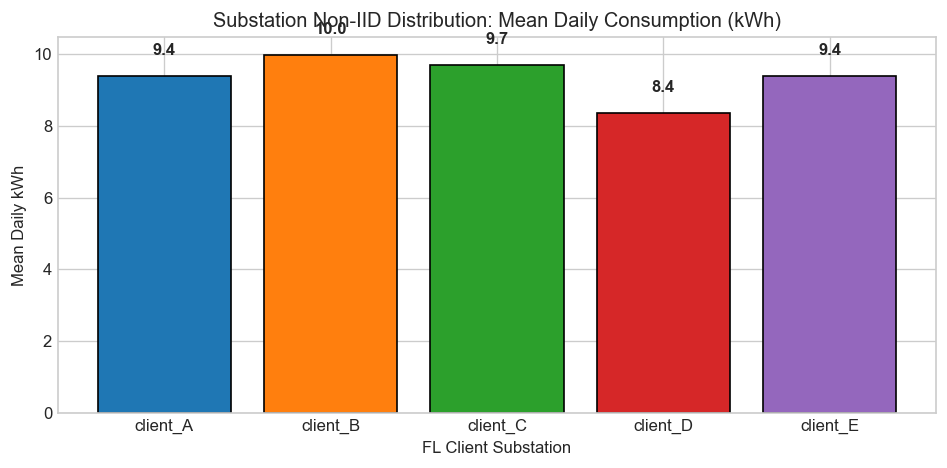

In [6]:
import json

summary_path = workspace_root / "data" / "processed" / "sgcc_partition_summary.json"

if summary_path.exists():
    with open(summary_path, "r") as f:
        summary_data = json.load(f)
    
    clients_info = summary_data["clients"]
    df_clients = pd.DataFrame.from_dict(clients_info, orient="index")
    print("=== Substation Client Vault Summary ===")
    display_cols = ["client_id", "meters_count", "theft_rate_pct", "mean_daily_kwh", "extracted_sequences", "privacy_firewall"]
    print(df_clients[display_cols].to_string(index=False))
    
    # Plot non-IID characteristics
    fig, ax = plt.subplots(figsize=(8, 4))
    bars = ax.bar(df_clients['client_id'], df_clients['mean_daily_kwh'], 
                  color=['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728', '#9467bd'], edgecolor='black')
    ax.set_title('Substation Non-IID Distribution: Mean Daily Consumption (kWh)')
    ax.set_ylabel('Mean Daily kWh')
    ax.set_xlabel('FL Client Substation')
    for b in bars:
        h = b.get_height()
        ax.text(b.get_x() + b.get_width()/2., h + 0.5, f"{h:.1f}", ha='center', va='bottom', fontweight='bold')
    plt.tight_layout()
    plt.show()

## 5. Summary & Verification

The preprocessed vaults ensure:
- **Zero data leakage**: Scalers are fitted per client or on training partitions only.
- **Multivariate inputs**: 11 features capture both temporal dynamics and operational flags.
- **Non-IID realism**: Substations exhibit strong domain diversity, setting the stage for federated evaluation.